KUMARA P.K.M.P. :  230353N

Git : https://github.com/minsarapasindu2003-del/CV_assignment_03

##### 1. Neural Network

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from datasets import load_dataset

# Download CIFAR-10 from Hugging Face (fast mirror)
ds = load_dataset("uoft-cs/cifar10")

# Convert images to normalized tensors (same normalization as original code given)
def to_tensors(split):
    imgs = np.stack([np.array(im) for im in ds[split]['img']])   # shape (N, 32, 32, 3)
    x = torch.from_numpy(imgs).permute(0, 3, 1, 2).float() / 255.0
    x = (x - 0.5) / 0.5
    y = torch.tensor(ds[split]['label'])
    return x, y

x_tr, y_tr = to_tensors('train')
x_te, y_te = to_tensors('test')

batch_size = 50
trainset = torch.utils.data.TensorDataset(x_tr, y_tr)
testset  = torch.utils.data.TensorDataset(x_te, y_te)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader  = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

print("Done:", x_tr.shape, x_te.shape)

c:\Users\minsa\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\minsa\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\minsa\.cache\huggingface\hub\datasets--uoft-cs--cifar10. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an admini

Done: torch.Size([50000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


Epoch 1/10, Loss: 1.9005
Epoch 2/10, Loss: 1.7168
Epoch 3/10, Loss: 1.6506
Epoch 4/10, Loss: 1.6032
Epoch 5/10, Loss: 1.5631
Epoch 6/10, Loss: 1.5296
Epoch 7/10, Loss: 1.4994
Epoch 8/10, Loss: 1.4722
Epoch 9/10, Loss: 1.4482
Epoch 10/10, Loss: 1.4262


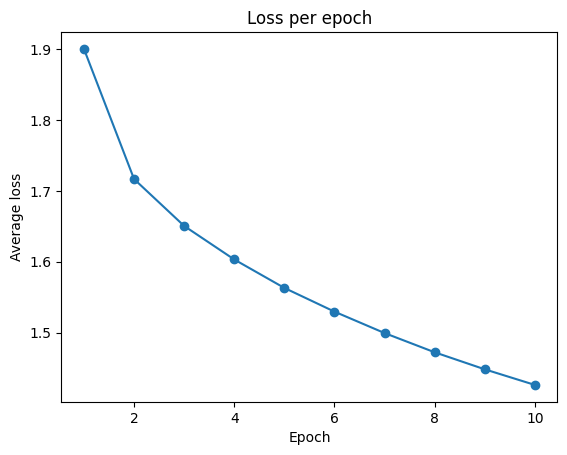

Training accuracy: 51.74%
Test accuracy: 47.54%


In [ ]:
#new network parameters
Din = 3 * 32 * 32   # 3072
H = 100             # hidden nodes
K = 10              # classes
std = 1e-2

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10     # epochs
lr = 0.1
lr_decay = 0.9
reg = 0

loss_history = []

def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))

def forward(x):
    h = sigmoid(x.mm(w1) + b1)
    scores = h.mm(w2) + b2
    return h, scores

#Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, scores = forward(x_train)

        # Softmax to subtract max for numerical stability
        scores_shifted = scores - scores.max(dim=1, keepdim=True).values
        exp_scores = torch.exp(scores_shifted)
        probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)

        # Cross entropy loss
        loss = -(1.0 / Ntr) * torch.sum(y_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dscores = (probs - y_onehot) / Ntr
        dw2 = h.t().mm(dscores) + 2 * reg * w2
        db2 = dscores.sum(dim=0)
        dh = dscores.mm(w2.t())
        dz1 = dh * h * (1 - h)            # sigmoid derivative
        dw1 = x_train.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t+1}/{iterations}, Loss: {running_loss/len(trainloader):.4f}")
    lr *= lr_decay

# Plot loss
epoch_avg = np.array(loss_history).reshape(10, -1).mean(axis=1)
plt.plot(range(1, 11), epoch_avg, marker='o')
plt.xlabel("Epoch"); plt.ylabel("Average loss"); plt.title("Loss per epoch")
plt.show()

# Accuracy helper
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, scores = forward(x)
            pred = torch.argmax(scores, dim=1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()
    return 100 * correct / total

print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")

Here I used Hugging Face loader instead torchvision keeping the same normalization. I add one hidden layer with 100 nodes and sigmoid activation. Update std to 1e-2 and lr = 0.1 and decay as 0.9. Also used softmax cross entropy loss.  Finally measure training accuaracy as 51.74% and test accuracy as 47.54%. The gap around 4% show some mild overfitting. Accuaracy is low because a dense network ignore the image structure. So for increase accuracy CNN better. 

##### 2. CNN

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Data
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # MNIST mean and std
])
train_data = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_data = datasets.MNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

# LeNet-5 implement
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2),  # 28x28 -> 28x28 here padding done at convolution
            nn.Tanh(),
            nn.AvgPool2d(2),                            # -> 14x14
            nn.Conv2d(6, 16, kernel_size=5),            # -> 10x10
            nn.Tanh(),
            nn.AvgPool2d(2),                            # -> 5x5
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

# function for training evaluation purpose
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

def train_model(model, epochs=10, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

        # Measure train and test metrics at the end of each epoch
        train_loss, train_acc = evaluate(model, train_loader, criterion)
        test_loss, test_acc = evaluate(model, test_loader, criterion)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss {train_loss:.4f}, Acc {train_acc:.4f} | "
              f"Test Loss {test_loss:.4f}, Acc {test_acc:.4f}")
    return model, history

# Train LeNet-5
lenet, lenet_history = train_model(LeNet5())
print(f"\nLeNet-5 final train accuracy: {lenet_history['train_acc'][-1]:.4f}")
print(f"LeNet-5 final test accuracy:  {lenet_history['test_acc'][-1]:.4f}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 422kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.92MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.3MB/s]


Epoch 1/10 | Train Loss 0.0778, Acc 0.9774 | Test Loss 0.0768, Acc 0.9763
Epoch 2/10 | Train Loss 0.0504, Acc 0.9844 | Test Loss 0.0510, Acc 0.9839
Epoch 3/10 | Train Loss 0.0411, Acc 0.9876 | Test Loss 0.0486, Acc 0.9848
Epoch 4/10 | Train Loss 0.0368, Acc 0.9882 | Test Loss 0.0480, Acc 0.9841
Epoch 5/10 | Train Loss 0.0217, Acc 0.9933 | Test Loss 0.0369, Acc 0.9889
Epoch 6/10 | Train Loss 0.0208, Acc 0.9934 | Test Loss 0.0354, Acc 0.9887
Epoch 7/10 | Train Loss 0.0183, Acc 0.9946 | Test Loss 0.0388, Acc 0.9878
Epoch 8/10 | Train Loss 0.0164, Acc 0.9949 | Test Loss 0.0366, Acc 0.9875
Epoch 9/10 | Train Loss 0.0129, Acc 0.9958 | Test Loss 0.0346, Acc 0.9889
Epoch 10/10 | Train Loss 0.0121, Acc 0.9962 | Test Loss 0.0381, Acc 0.9889

LeNet-5 final train accuracy: 0.9962
LeNet-5 final test accuracy:  0.9889


Here built LeNet5 network in pytorch for MNIST. It has two convolution layers with 6 and 16 filters. Each filter is 5 by 5 size. It use tanh activation and average pooling. After that it has three fully connected layers of size 120, 84 and 10. Here I use padding of 2 in the first convolution layer to fit 28 by 28 images to the network. (since Lenet5 design to 32 by 32 input ).
After 10 epoches training accuracy is 99.62% and test accuracy is 98.89%. After about 5 epoches test accuracy stop improving while training loss falling. This show small amount of overfitting. 

In [ ]:
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                            # 28 -> 14
            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                            # 14 -> 7
            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),                            # 7 -> 3
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128 * 3 * 3, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

# Same conditions as LeNet-5: 10 epochs, Adam, lr=0.001, batch size 64
modern, modern_history = train_model(ModernCNN())
print(f"\nModern CNN final train accuracy: {modern_history['train_acc'][-1]:.4f}")
print(f"Modern CNN final test accuracy:  {modern_history['test_acc'][-1]:.4f}")

Epoch 1/10 | Train Loss 0.0788, Acc 0.9743 | Test Loss 0.0716, Acc 0.9752
Epoch 2/10 | Train Loss 0.0245, Acc 0.9922 | Test Loss 0.0288, Acc 0.9909
Epoch 3/10 | Train Loss 0.0193, Acc 0.9941 | Test Loss 0.0257, Acc 0.9907
Epoch 4/10 | Train Loss 0.0197, Acc 0.9936 | Test Loss 0.0307, Acc 0.9895
Epoch 5/10 | Train Loss 0.0121, Acc 0.9962 | Test Loss 0.0227, Acc 0.9929
Epoch 6/10 | Train Loss 0.0142, Acc 0.9953 | Test Loss 0.0276, Acc 0.9915
Epoch 7/10 | Train Loss 0.0105, Acc 0.9971 | Test Loss 0.0220, Acc 0.9926
Epoch 8/10 | Train Loss 0.0224, Acc 0.9923 | Test Loss 0.0373, Acc 0.9881
Epoch 9/10 | Train Loss 0.0101, Acc 0.9967 | Test Loss 0.0250, Acc 0.9912
Epoch 10/10 | Train Loss 0.0094, Acc 0.9969 | Test Loss 0.0290, Acc 0.9915

Modern CNN final train accuracy: 0.9969
Modern CNN final test accuracy:  0.9915


Here built a CNN with three convolution blocks. The blocks have 32, 64 and 128 filters. Each filter is 3 by 3. Each block use batch normalization, ReLU and max pooling. After the blocks there is a dropout of 0.5 and one linear layer. CNN trained on same conditions as same as LeNet 5 to fair comparison. After 10 epochs training accuracy was 99.69% and test accuracy was 99.15%. Here this model approach 99% test accuracy by epoch 2 while Lenet 5 need 5 epochs. There is some small variation in test accuracy in epoch by epoch due to batch normalization and Adam. 

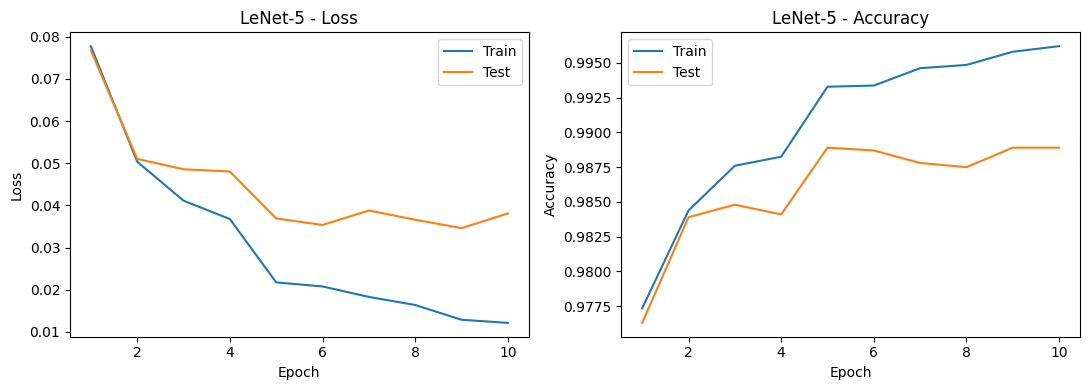

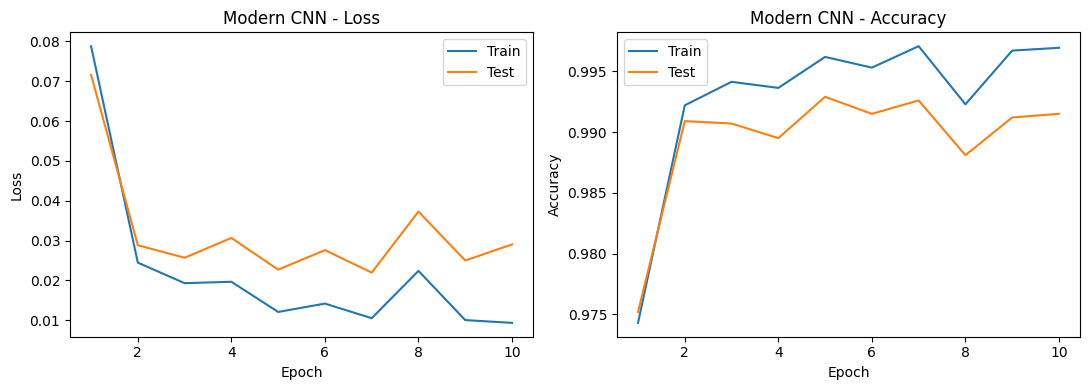

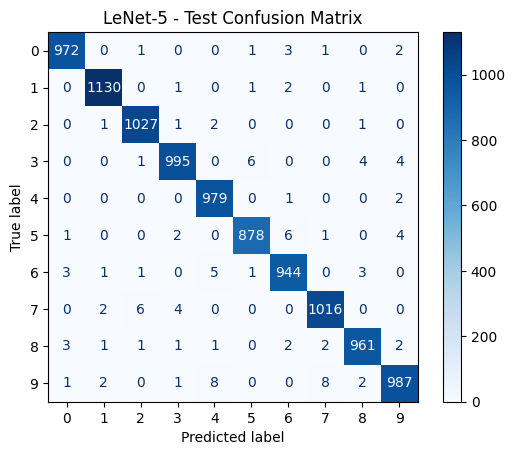

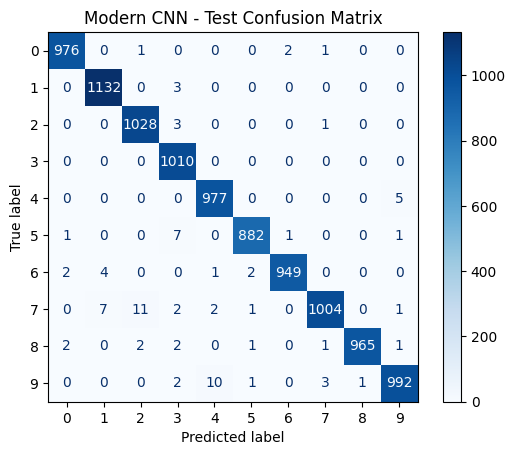

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#Per-epoch accuracy and loss plots
def plot_history(history, name):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["test_loss"], label="Test")
    axes[0].set_title(f"{name} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["test_acc"], label="Test")
    axes[1].set_title(f"{name} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(lenet_history, "LeNet-5")
plot_history(modern_history, "Modern CNN")

#Confusion matrices on the test set
def plot_confusion(model, name):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images.to(device))
            all_preds.extend(outputs.argmax(1).cpu().numpy())
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=range(10))
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{name} - Test Confusion Matrix")
    plt.show()

plot_confusion(lenet, "LeNet-5")
plot_confusion(modern, "Modern CNN")

The modern CNN has lower loss than LeNet 5. Also modern CNN learn faster and end higher accuracy. Both models show little overfit which is acceptable. Also modern CNN has about 105k parameters while LeNet5 has about 62k. So modern CNN needs more computation. 

##### 3. Classification

In [1]:
import os, urllib.request, zipfile
import torch, torch.nn as nn, torch.optim as optim
from torch.optim import lr_scheduler
from torchvision import datasets, models, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Download dataset
if not os.path.exists("hymenoptera_data"):
    url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
    urllib.request.urlretrieve(url, "hymenoptera_data.zip")
    zipfile.ZipFile("hymenoptera_data.zip").extractall(".")

# Data
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tfms = {
    "train": transforms.Compose([transforms.RandomResizedCrop(224),
                                 transforms.RandomHorizontalFlip(),
                                 transforms.ToTensor(), norm]),
    "val": transforms.Compose([transforms.Resize(256),
                               transforms.CenterCrop(224),
                               transforms.ToTensor(), norm]),
}
data = {p: datasets.ImageFolder(f"hymenoptera_data/{p}", tfms[p]) for p in tfms}
loaders = {p: torch.utils.data.DataLoader(data[p], batch_size=4,
                                          shuffle=(p == "train"), num_workers=2)
           for p in data}
print("Classes:", data["train"].classes)


#Training loop
def train(model, optimizer, scheduler, epochs=25):
    criterion = nn.CrossEntropyLoss()
    best_acc = 0.0
    for epoch in range(epochs):
        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()
            correct, total_loss = 0, 0.0
            for x, y in loaders[phase]:
                x, y = x.to(device), y.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == "train"):
                    out = model(x)
                    loss = criterion(out, y)
                    if phase == "train":
                        loss.backward()
                        optimizer.step()
                total_loss += loss.item() * x.size(0)
                correct += (out.argmax(1) == y).sum().item()
            if phase == "train":
                scheduler.step()
            n = len(data[phase])
            acc = correct / n
            print(f"Epoch {epoch+1:2d} {phase:5s} loss {total_loss/n:.4f} acc {acc:.4f}")
            if phase == "val":
                best_acc = max(best_acc, acc)
    return best_acc


def get_model():
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    return model


# Fine-tuning: train ALL layers
print("\n Fine-tuning ")
model_ft = get_model()
model_ft.fc = nn.Linear(model_ft.fc.in_features, 2)   # new 2-class head
model_ft = model_ft.to(device)
opt = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
sched = lr_scheduler.StepLR(opt, step_size=7, gamma=0.1)
acc_ft = train(model_ft, opt, sched)

# Feature extractor: freeze backbone, train only last layer
print("\n Feature extractor ")
model_fe = get_model()
for p in model_fe.parameters():
    p.requires_grad = False                            # freeze everything
model_fe.fc = nn.Linear(model_fe.fc.in_features, 2)    # new head (trainable)
model_fe = model_fe.to(device)
opt = optim.SGD(model_fe.fc.parameters(), lr=0.001, momentum=0.9)
sched = lr_scheduler.StepLR(opt, step_size=7, gamma=0.1)
acc_fe = train(model_fe, opt, sched)

# Results
print("\nRESULTS (best validation accuracy) ")
print(f"(a) Fine-tuning       : {acc_ft:.4f}")
print(f"(b) Feature extractor : {acc_fe:.4f}")

Classes: ['ants', 'bees']

 Fine-tuning 
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 141MB/s]


Epoch  1 train loss 0.5700 acc 0.7131
Epoch  1 val   loss 0.2210 acc 0.9281
Epoch  2 train loss 0.6277 acc 0.7336
Epoch  2 val   loss 0.3085 acc 0.8627
Epoch  3 train loss 0.4680 acc 0.8033
Epoch  3 val   loss 0.5521 acc 0.8170
Epoch  4 train loss 0.4335 acc 0.8115
Epoch  4 val   loss 0.2287 acc 0.9150
Epoch  5 train loss 0.4394 acc 0.8320
Epoch  5 val   loss 0.5953 acc 0.7908
Epoch  6 train loss 0.6213 acc 0.7746
Epoch  6 val   loss 0.3872 acc 0.8039
Epoch  7 train loss 0.5418 acc 0.7746
Epoch  7 val   loss 0.1826 acc 0.9281
Epoch  8 train loss 0.3690 acc 0.8238
Epoch  8 val   loss 0.2060 acc 0.9085
Epoch  9 train loss 0.3833 acc 0.8525
Epoch  9 val   loss 0.2160 acc 0.9150
Epoch 10 train loss 0.3663 acc 0.8689
Epoch 10 val   loss 0.2062 acc 0.9085
Epoch 11 train loss 0.2609 acc 0.9057
Epoch 11 val   loss 0.1630 acc 0.9412
Epoch 12 train loss 0.2246 acc 0.8893
Epoch 12 val   loss 0.1613 acc 0.9477
Epoch 13 train loss 0.2054 acc 0.9221
Epoch 13 val   loss 0.1627 acc 0.9477
Epoch 14 tra

Here used pre trained ResNet 18 to classify ants and bees from hymenoptera dataset. It has 244 training images and 153 validation images. Here I replace the last layer with a 2 class layer.

In fine tuning, train all layers and in feature extraction frose all layers except last one. Both used SGD with lr = 0.001 and momentum 0.9. Both methods reach the same best validation accuracy of 95.42%. Fine tuning was unstable in early epochs but feature extraction was more stable and fast to train. 

As my opinion feature extraction is the better choice here because it is faster and just as accurate. 